# 01 — Data Cleaning & Exploratory Data Analysis
**Endothelial disease classification and severity — NEBSL corneal dataset**

This notebook:
1. Loads the combined research dataset
2. Cleans it (failed Konan readings, flagged rows, messy text fields, outliers)
3. Defines the classification and severity targets
4. Builds donor groups for leakage-free splitting
5. Runs EDA to decide which features are usable
6. Saves `Cleaned_Dataset.csv` and `Feature_Decisions.csv` for **02_Feature_Engineering**

## 1. Setup

In [2]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, mannwhitneyu
from sklearn.feature_selection import mutual_info_classif
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import classification_report

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid")


excel_path = r"C:\Users\minsa_\Downloads\Combined_Research_Dataset_Final.xlsx"
IMAGE_DIR  = r"C:\Users\minsa_\Downloads\filtered-new\filtered-new"
OUTPUT_DIR = os.path.dirname(excel_path)                     

## 2. Load data and first look

In [3]:
xls = pd.ExcelFile(excel_path)
print("Sheets:", xls.sheet_names)

df = pd.read_excel(xls, sheet_name="Combined_Dataset")
review_flags = pd.read_excel(xls, sheet_name="Review_Flags")
ORIGINAL_COLS = df.columns.tolist()

print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Sheets: ['Combined_Dataset', 'Change_Log', 'Review_Flags', 'Notes']
Rows: 1054 | Columns: 85


,Tissue_ID,Eye,Image_ID,Disease_Label,Disease_Severity,ECD_CD_cells_per_mm2,CV,HEX_percent,SD,Total_Cell_Count,Total_Area_um2,Epithelium_Findings,Epithelium_Severity,Stroma_Findings,Stroma_Severity,Descemet_Findings,Descemet_Severity,Endothelium_Findings,Endothelium_Severity,Additional_Findings,Tissue_Grade,Overall_Donor_Quality,Transplant_Suitability,Suitability_Reason,Primary_COD,Donor_Age,Tissue_Serial,Linkage_Status,Source_PDF,PDF_Pages,Konan_Report_File,SP_Image_File,Cell_Image_File,Konan_Raw_CorneaID,Konan_Exam_Date,Konan_Mean_Cell_Area_um2,Konan_Comments,Donor_Sex,Admitting_Diagnosis,Death_Date_Time,Preservation_Date_Time,Death_to_Preservation_Time,Storage_Medium,Serology_HBsAg,Serology_HCV,Serology_HIV,Serology_VDRL,Lens_Status,Form_ECD_cells_per_mm2,Intended_Use,Tissue_Outcome,Recipient_Age,Recipient_Eye,Recipient_Indication,Request_Indication,Previous_Grafts,Primary_Procedure,Secondary_Procedures,Surgery_Date,Donor_Graft_Size_mm,Recipient_Bed_Size_mm,Suture_Technique,Intraop_Complications,Death_to_Surgery_Days,Request_Reg_No,Request_Issue_No,Request_Date,Proposed_Op_Date,Request_Urgency,Request_Indication_Type,Recipient_Sex,VA_Operative_Eye,VA_Fellow_Eye,Requested_Grade,Planned_Procedure,Requesting_Surgeon,Requesting_Hospital,Request_to_Surgery_Days,Grade_Request_Met,Dataset_Part,Tissue_Grade_Source,Disease_Label_Source,Needs_Review,Review_Notes,Merge_Filled_Columns
0,NEB-2020-09-12654 R,Right,NEB-2020-09-12654 R_SP,Normal,NaN,2132.0,33.0,58.0,153.0,24.0,11266.0,Clear and intact,NaN,Clear; arcus,Mild,Folds,Mild,NaN,NaN,Rim 3.5; cornea diameter 11 mm; corneoscleral 18 mm,B,NaN,NaN,NaN,Disseminated carcinoma of oesophagus,57.0,12654,Linked: form + Konan + image,12654R.pdf,6.0,NEB-2020-09-12654 RT.txt,NEB-2020-09-12654 R_SP.jpg,NEB-2020-09-12654 R_C.jpg,NEB-2020-09-12654 R,2020-09-14 0:00:00,469.0,T.H.KU/GALA-WD.50-ONCOLOGY,Male,Carcinoma of oesophagus,2020-09-13 12:20:00,2020-09-13 14:50:00,2 h 30 min,Eusol-C,Negative,Negative,Negative,Negative,NaN,2132,NaN,NaN,NaN,Right,NaN,Therapeutic,NaN,Lamellar keratoplasty (DALK),NaN,2020-09-18 0:00:00,8.25,8,Interrupted,NaN,5.0,NaN,NaN,NaN,NaN,NaN,Therapeutic,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Graded set (eye-bank forms),Eye-bank form,Eye-bank form,NaN,NaN,NaN
1,NEB-2020-09-12655 L,Left,NEB-2020-09-12655 L_SP,Folds,Moderate,2212.0,33.0,47.0,147.0,70.0,31637.0,"Exposure; peripheral (""mild exposure"")",Mild,Arcus,NaN,NaN,NaN,NaN,NaN,Rim 3.5; cornea diameter 11 mm; corneoscleral 18 mm,B,NaN,NaN,NaN,Disseminated carcinoma of oesophagus,57.0,12655,Linked: form + Konan + image,12655L.pdf,5.0,NEB-2020-09-12655 LT.txt,NEB-2020-09-12655 L_SP.jpg,NEB-2020-09-12655 L_C.jpg,NEB-2020-09-12655 L,2020-09-14 0:00:00,452.0,T.H.KU/GALA-WD.50-ONCOLOGY,Male,Carcinoma of oesophagus,NaN,NaN,2 h 30 min,NaN,NaN,NaN,NaN,NaN,NaN,2212,NaN,Cornea expired 27-09-2020 (handwritten note),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Graded set (eye-bank forms),Eye-bank form,Eye-bank form,NaN,NaN,NaN
2,NEB-2020-09-12656 R,Right,NEB-2020-09-12656 R_SP,Normal,NaN,2538.0,35.0,53.0,137.0,136.0,53575.0,Clear and intact,NaN,Clear; arcus,Mild,Folds,Mild,Stress lines; central; few,NaN,Rim 1.5-2; cornea diameter 11 mm; corneoscleral 17 mm; clear area 8 mm,A,Excellent,Suitable,NaN,Basilar artery thrombosis + cerebral infarction,51.0,12656,Linked: form + Konan + image,12656R.pdf,4.0,NEB-2020-09-12656 RT.txt,NEB-2020-09-12656 R_SP.jpg,NEB-2020-09-12656 R_C.jpg,NEB-2020-09-12656 R,2020-09-14 0:00:00,394.0,T.H.KU/GALA-WD.40-NEUROLOGY,Female,HT + polyarthritis (as read),2020-09-13 18:15:00,2020-09-13 20:30:00,2 h 15 min,Eusol-C,Negative,Negative,Negative,Negative,Phakic,2538,PKP - MK unit NEH 15/09/2020,NaN,NaN,Left (request form),L/E trauma / decompensated graft (as read),Optical,1,"PK (planned, request form)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Optical,NaN,NaN,NaN,NaN,PK,NaN,NaN,NaN,NaN,Graded set (eye-bank forms),Eye-bank form,Eye-bank form,NaN

In [4]:
column_info = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Missing": df.isna().sum().values,
    "Missing_%": (df.isna().mean() * 100).round(1).values,
    "Unique": df.nunique().values,
})
column_info

,Column,Data_Type,Missing,Missing_%,Unique
0,Tissue_ID,str,0,0.0,1054
1,Eye,str,0,0.0,2
2,Image_ID,str,9,0.9,1045
3,Disease_Label,str,0,0.0,21
4,Disease_Severity,str,509,48.3,3
...,...,...,...,...,...
80,Tissue_Grade_Source,str,17,1.6,1
81,Disease_Label_Source,str,0,0.0,1
82,Needs_Review,float64,1054,100.0,0
83,Review_Notes,str,766,72.7,160


In [5]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate Tissue_IDs:", df["Tissue_ID"].duplicated().sum())
print("Duplicate SP image files:", df["SP_Image_File"].dropna().duplicated().sum())
print("\nLinkage status:")
df["Linkage_Status"].value_counts()

Exact duplicate rows: 0
Duplicate Tissue_IDs: 0
Duplicate SP image files: 0

Linkage status:


Linkage_Status
Linked: form + Konan + image                                  495
Konan report + image only (no form)                           459
Form only (no Konan/image)                                     87
Linked: form + Konan + image (Konan analysis empty - CD 0)      7
Konan report + image only, no form (Konan count = 0)            4
Linked: form + Konan + image (Konan count = 0)                  1
Konan image only (no report, no form)                           1
Name: count, dtype: int64

## 3. Data cleaning
### 3.1 Failed Konan analyses (ECD = 0)
A value of 0 for ECD / CV / HEX / SD means the Konan analysis failed (no cells counted). These are missing values, not real measurements.

In [6]:
konan_cols = ["ECD_CD_cells_per_mm2", "CV", "HEX_percent", "SD",
              "Total_Cell_Count", "Total_Area_um2", "Konan_Mean_Cell_Area_um2"]

zero_mask = df["ECD_CD_cells_per_mm2"].eq(0)
print("Rows with failed Konan analysis (ECD = 0):", zero_mask.sum())
display(df.loc[zero_mask, ["Tissue_ID", "Disease_Label", "Linkage_Status"] + konan_cols[:4]])

df.loc[zero_mask, konan_cols] = np.nan
df["Has_Konan"] = df["ECD_CD_cells_per_mm2"].notna()
df["Has_Konan"].value_counts()

Rows with failed Konan analysis (ECD = 0): 4


,Tissue_ID,Disease_Label,Linkage_Status,ECD_CD_cells_per_mm2,CV,HEX_percent,SD
676,NEB-2023-03-14825 R,Poor cornea,"Konan report + image only, no form (Konan count = 0)",0.0,0.0,0.0,0.0
817,NEB-2023-05-15117 R,Poor cornea,"Konan report + image only, no form (Konan count = 0)",0.0,0.0,0.0,0.0
832,NEB-2023-06-15153 R,Poor cornea,"Konan report + image only, no form (Konan count = 0)",0.0,0.0,0.0,0.0
889,NEB-2023-07-15267 R,Poor cornea,"Konan report + image only, no form (Konan count = 0)",0.0,0.0,0.0,0.0


Has_Konan
True     999
False     55
Name: count, dtype: int64

### 3.2 Rows flagged during dataset merging
The `Review_Flags` sheet lists rows where the eye doesn't match the linked image, or the Konan ECD doesn't match the ECD written on the eye-bank form.

* **Eye mismatch** → the linked image may belong to the other eye, so the image link is removed (the row stays for tabular use).
* **ECD mismatch** → the Konan value is the machine measurement, so it is kept; the row is flagged.

In [7]:
display(review_flags)

flag_ids = review_flags["Tissue_ID"].astype(str).str.strip()
eye_ids = flag_ids[review_flags["Flag"].str.contains("Eye", case=False)]
ecd_ids = flag_ids[review_flags["Flag"].str.contains("ECD", case=False)]

df["Flag_Eye_Mismatch"] = df["Tissue_ID"].isin(eye_ids)
df["Flag_ECD_Mismatch"] = df["Tissue_ID"].isin(ecd_ids)
print("Eye mismatches found in data:", df["Flag_Eye_Mismatch"].sum())
print("ECD mismatches found in data:", df["Flag_ECD_Mismatch"].sum())

df.loc[df["Flag_Eye_Mismatch"], ["Image_ID", "SP_Image_File", "Cell_Image_File"]] = np.nan

display(df.loc[df["Flag_ECD_Mismatch"], ["Tissue_ID", "ECD_CD_cells_per_mm2", "Form_ECD_cells_per_mm2"]])

,Tissue_ID,Flag,Detail
0,12346 R (year/month unknown),Row only in research CSV,Not present in Disease_Labels file; kept as-is
1,NEB-2020-09-12683 L,Eye mismatch,Tissue eye L but filled Image_ID is NEB-2020-09-12683 R_SP
2,NEB-2020-10-12706 R,ECD mismatch,Filled ECD 2882 vs Form_ECD 2822
3,NEB-2020-10-12726 R,Eye mismatch,Tissue eye R but filled Image_ID is NEB-2020-10-12726 L_SP
4,NEB-2020-10-12738 R,ECD mismatch,Filled ECD 2778 vs Form_ECD 2513
5,NEB-2020-10-12739 L,ECD mismatch,Filled ECD 2364 vs Form_ECD 2525
6,NEB-2020-10-12748 L,ECD mismatch,Filled ECD 2967 vs Form_ECD 2994
7,NEB-2020-10-12749 R,ECD mismatch,Filled ECD 3236 vs Form_ECD 3145
8,NEB-2025-10-17576 L,Eye mismatch,Tissue eye L but filled Image_ID is NEB-2025-10-17576 R_SP


Eye mismatches found in data: 3
ECD mismatches found in data: 5


,Tissue_ID,ECD_CD_cells_per_mm2,Form_ECD_cells_per_mm2
52,NEB-2020-10-12706 R,2882.0,2822
82,NEB-2020-10-12738 R,2778.0,2513
83,NEB-2020-10-12739 L,2364.0,2525
92,NEB-2020-10-12748 L,2967.0,2994
93,NEB-2020-10-12749 R,3236.0,3145


### 3.3 Clean transcribed text fields
Form fields contain transcription notes such as `(as read)`, `(verify)`, `(release form)`. These are stripped and the values standardised.

In [8]:
def clean_tag(s):
    if pd.isna(s): return np.nan
    s = re.sub(r"\(.*?\)", "", str(s))
    s = re.sub(r"\b(verify|as read)\b", "", s, flags=re.I)
    return s.strip(" ;,-").strip() or np.nan

def to_minutes(s):
    if pd.isna(s): return np.nan
    s = str(s).lower()
    h = re.search(r"(\d+)\s*h", s); m = re.search(r"(\d+)\s*min", s)
    if not h and not m: return np.nan
    return (int(h.group(1)) if h else 0) * 60 + (int(m.group(1)) if m else 0)

df["Death_to_Preservation_Min"] = df["Death_to_Preservation_Time"].apply(to_minutes)
df["Donor_Sex_Clean"] = (df["Donor_Sex"].apply(clean_tag)
                         .str.extract(r"(Male|Female)", flags=re.I)[0].str.title())
df["Lens_Status_Clean"] = (df["Lens_Status"].apply(clean_tag)
                           .str.extract(r"(Pseudophakic|Aphakic|Phakic)", flags=re.I)[0].str.title())
df["Eye_Right"] = (df["Eye"] == "Right").astype(int)

for c in ["Death_to_Preservation_Min", "Donor_Sex_Clean", "Lens_Status_Clean"]:
    print(f"{c}: missing = {df[c].isna().sum()}")
display(df["Donor_Sex_Clean"].value_counts(dropna=False))
display(df["Lens_Status_Clean"].value_counts(dropna=False))
df["Death_to_Preservation_Min"].describe()

Death_to_Preservation_Min: missing = 476
Donor_Sex_Clean: missing = 488
Lens_Status_Clean: missing = 481


Donor_Sex_Clean
NaN       488
Male      369
Female    197
Name: count, dtype: int64

Lens_Status_Clean
Phakic          541
NaN             481
Pseudophakic     32
Name: count, dtype: int64

count    578.000000
mean     131.384083
std       50.070016
min       20.000000
25%      100.000000
50%      125.000000
75%      150.000000
max      325.000000
Name: Death_to_Preservation_Min, dtype: float64

### 3.4 Outlier and plausibility check
Values are only **flagged**, not removed: extreme values are expected in FECD. Ranges are broad physiological limits for donor endothelium.

In [9]:
plausible = {
    "ECD_CD_cells_per_mm2": (300, 4500),
    "CV": (15, 80),
    "HEX_percent": (10, 90),
    "SD": (20, 1000),
    "Donor_Age": (0, 100),
    "Death_to_Preservation_Min": (0, 24 * 60),
}
df["Flag_Implausible"] = False
for col, (lo, hi) in plausible.items():
    bad = df[col].notna() & ~df[col].between(lo, hi)
    df.loc[bad, "Flag_Implausible"] = True
    print(f"{col:28s} outside [{lo}, {hi}]: {bad.sum()}")

display(df.loc[df["Flag_Implausible"],
               ["Tissue_ID", "Disease_Label"] + list(plausible.keys())])

ECD_CD_cells_per_mm2         outside [300, 4500]: 0
CV                           outside [15, 80]: 0
HEX_percent                  outside [10, 90]: 0
SD                           outside [20, 1000]: 0
Donor_Age                    outside [0, 100]: 0
Death_to_Preservation_Min    outside [0, 1440]: 0


,Tissue_ID,Disease_Label,ECD_CD_cells_per_mm2,CV,HEX_percent,SD,Donor_Age,Death_to_Preservation_Min


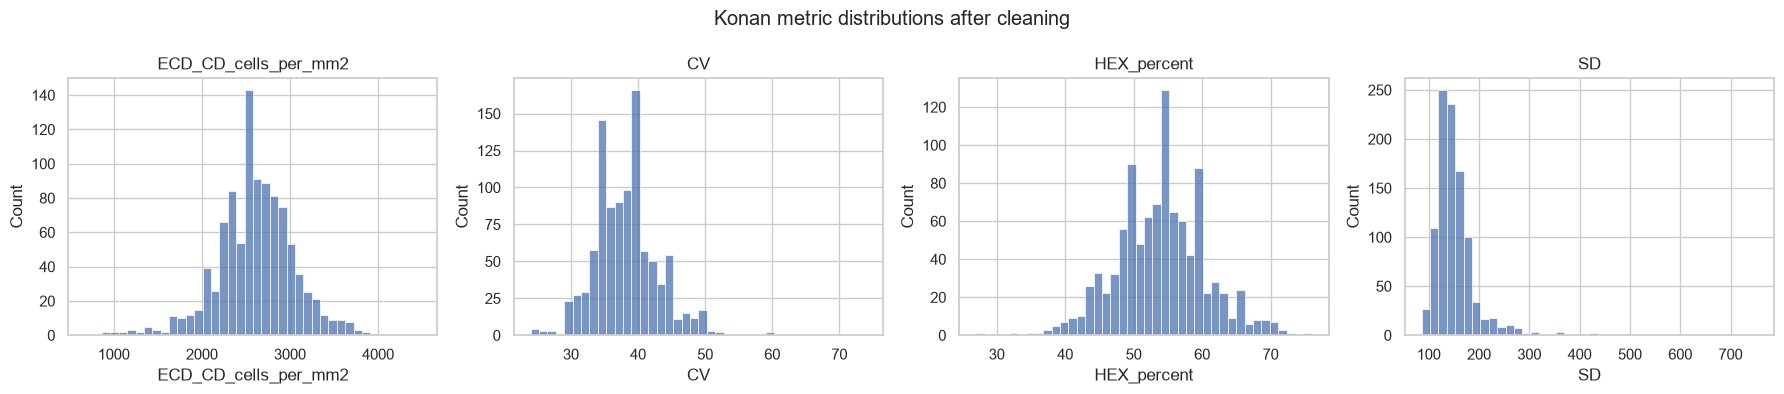

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["ECD_CD_cells_per_mm2", "CV", "HEX_percent", "SD"]):
    sns.histplot(df[col].dropna(), bins=40, ax=ax)
    ax.set_title(col)
plt.suptitle("Konan metric distributions after cleaning")
plt.tight_layout(); plt.show()

## 4. Target definition
`Disease_Label` holds `;`-separated findings. FECD almost always appears together with *Polymorphism and pleomorphism* and *Low cell density*, so these behave as **one endothelial-disease class**, not three independent labels.

In [11]:
label_str = df["Disease_Label"].fillna("").astype(str)

individual = label_str.str.split(";").explode().str.strip()
display(individual.value_counts().to_frame("Count"))

flags = {"FECD": "FECD", "LCD": "Low cell density",
         "POLY": "Polymorphism", "GUTT": "Guttata", "FOLDS": "Folds"}
for k, v in flags.items():
    df[f"has_{k}"] = label_str.str.contains(v, case=False)

print("FECD co-occurrence with Low cell density and Polymorphism:")
pd.crosstab(df["has_FECD"], [df["has_LCD"], df["has_POLY"]])

,Count
Disease_Label,
Normal,504
Folds,380
Polymorphism and pleomorphism,132
FECD,127
Low cell density,126
Guttata,100
Poor cornea,5
Not labelled (no CellChek report),1


FECD co-occurrence with Low cell density and Polymorphism:


has_LCD  False       True       
has_POLY False True  False True 
has_FECD                        
False      918     6     3     0
True         1     3     0   123

In [12]:
UNUSABLE = ["Poor cornea", "Not labelled (no CellChek report)"]

def primary_class(r):
    if r["Disease_Label"] in UNUSABLE:
        return np.nan
    if r["has_FECD"] or r["has_LCD"] or r["has_POLY"]:
        return "FECD/Endothelial"     # most clinically severe finding takes priority
    if r["has_GUTT"]:
        return "Guttata"
    if r["has_FOLDS"]:
        return "Folds"
    if r["Disease_Label"] == "Normal":
        return "Normal"
    return np.nan

df["Target_Class"] = df.apply(primary_class, axis=1)

# Severity: Moderate and Severe merged because Severe has only 14 rows
sev_map = {"Mild": "Mild", "Moderate": "Moderate+Severe", "Severe": "Moderate+Severe"}
df["Target_Severity"] = df["Disease_Severity"].map(sev_map)
df.loc[df["Target_Class"].eq("Normal"), "Target_Severity"] = "None"

print("Rows without a usable label (dropped):", df["Target_Class"].isna().sum())
display(df.loc[df["Target_Class"].isna(), ["Tissue_ID", "Disease_Label", "Disease_Severity"]])

df = df[df["Target_Class"].notna()].reset_index(drop=True)
print("Rows remaining:", len(df))

Rows without a usable label (dropped): 6


,Tissue_ID,Disease_Label,Disease_Severity
575,NEB-2025-11-17636 L,Poor cornea,Mild
590,NEB-2023-01-14657 R,Not labelled (no CellChek report),NaN
676,NEB-2023-03-14825 R,Poor cornea,NaN
817,NEB-2023-05-15117 R,Poor cornea,NaN
832,NEB-2023-06-15153 R,Poor cornea,NaN
889,NEB-2023-07-15267 R,Poor cornea,NaN


Rows remaining: 1048


,Count
Target_Class,
Normal,504
Folds,324
Guttata,84
FECD/Endothelial,136


,Count
Target_Severity,
None,504
Mild,474
Moderate+Severe,70


Target_Severity,Mild,Moderate+Severe,None
Target_Class,,,
Normal,0,0,504
Folds,295,29,0
Guttata,72,12,0
FECD/Endothelial,107,29,0


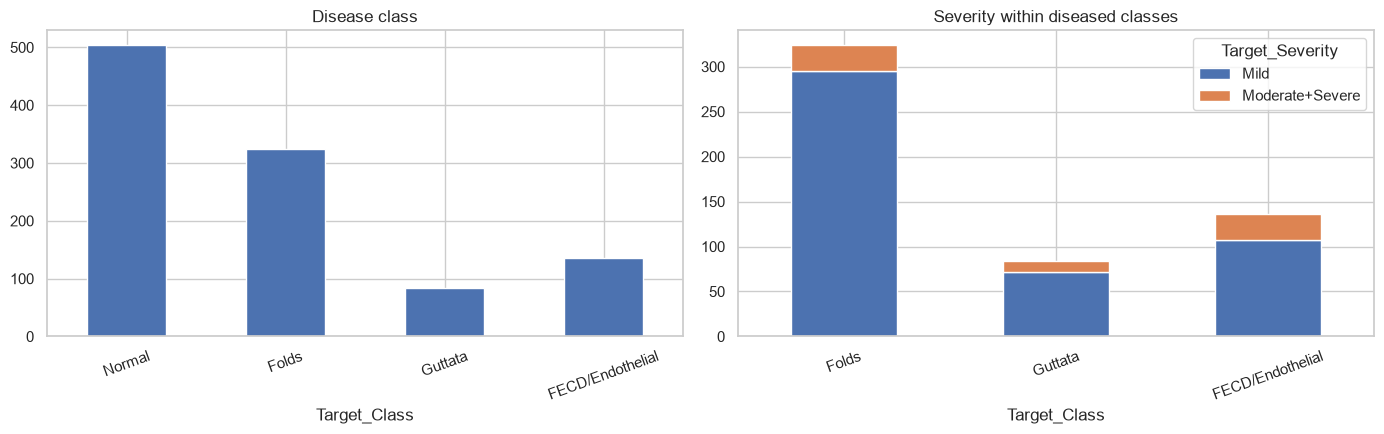

In [13]:
CLASS_ORDER = ["Normal", "Folds", "Guttata", "FECD/Endothelial"]
SEV_ORDER = ["Mild", "Moderate+Severe"]

display(df["Target_Class"].value_counts().reindex(CLASS_ORDER).to_frame("Count"))
display(df["Target_Severity"].value_counts().to_frame("Count"))
display(pd.crosstab(df["Target_Class"], df["Target_Severity"]).reindex(CLASS_ORDER))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
df["Target_Class"].value_counts().reindex(CLASS_ORDER).plot(kind="bar", ax=axes[0])
axes[0].set_title("Disease class"); axes[0].tick_params(axis="x", rotation=20)
pd.crosstab(df["Target_Class"], df["Target_Severity"]).reindex(CLASS_ORDER[1:])[SEV_ORDER] \
    .plot(kind="bar", stacked=True, ax=axes[1])
axes[1].set_title("Severity within diseased classes"); axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## 5. Donor grouping
Most donors contribute **both eyes**. Two eyes from one donor are highly correlated, so they must stay in the same train/test fold. Donors are identified by:
* identical death date-time + donor age (rows with eye-bank forms), or
* consecutive tissue numbers with opposite eyes (rows without forms).

In [14]:
df["Tissue_Num"] = df["Tissue_ID"].str.extract(r"-(\d{4,6})\s*[LR]?$")[0].astype(float)
df = df.sort_values("Tissue_Num").reset_index(drop=True)

key = df["Death_Date_Time"].astype(str) + "|" + df["Donor_Age"].astype(str)
has_key = df["Death_Date_Time"].notna() & df["Donor_Age"].notna()
df["Donor_Group"] = np.where(has_key, "D_" + key, "T_" + df["Tissue_ID"])

gap = df["Tissue_Num"].diff().fillna(99)
pair_ok = (gap == 1) & (df["Eye"] != df["Eye"].shift()) & (~has_key)
pair_id = (~pair_ok).cumsum()
df.loc[~has_key, "Donor_Group"] = "P_" + pair_id[~has_key].astype(str)

sizes = df["Donor_Group"].value_counts()
print("Donor groups:", df["Donor_Group"].nunique())
print(sizes.value_counts().sort_index().rename("n_groups").rename_axis("eyes_per_group").to_frame())

# do both eyes of a donor share the same class?
pairs = df[df["Donor_Group"].map(sizes) == 2].groupby("Donor_Group")["Target_Class"].nunique()
print(f"\nDonors with both eyes in the SAME class: {(pairs == 1).mean():.0%}")

Donor groups: 784
                n_groups
eyes_per_group          
1                    541
2                    233
3                      3
4                      4
5                      2
6                      1

Donors with both eyes in the SAME class: 52%


## 6. Exploratory data analysis

### 6.1 Numeric summary and Eye balance

In [15]:
num_feats = ["ECD_CD_cells_per_mm2", "CV", "HEX_percent", "SD", "Total_Cell_Count",
             "Total_Area_um2", "Konan_Mean_Cell_Area_um2", "Donor_Age", "Death_to_Preservation_Min"]
display(df[num_feats].describe().T.round(1))
display(pd.crosstab(df["Target_Class"], df["Eye"], normalize="index").round(2).reindex(CLASS_ORDER))

,count,mean,std,min,25%,50%,75%,max
ECD_CD_cells_per_mm2,999.0,2602.2,447.1,676.0,2342.0,2591.0,2874.0,4484.0
CV,999.0,38.2,5.0,24.0,35.0,38.0,41.0,74.0
HEX_percent,999.0,54.0,6.5,27.0,50.0,54.0,58.0,76.0
SD,998.0,152.7,47.7,86.0,127.0,144.0,164.0,753.0
Total_Cell_Count,952.0,107.0,16.4,10.0,104.0,108.0,113.0,204.0
Total_Area_um2,952.0,42265.1,9122.7,5071.0,37512.5,41464.5,46336.5,100692.0
Konan_Mean_Cell_Area_um2,952.0,400.3,96.6,223.0,350.0,386.0,428.0,1479.0
Donor_Age,1045.0,59.7,10.9,15.0,54.0,62.0,68.0,78.0
Death_to_Preservation_Min,577.0,131.4,50.1,20.0,100.0,125.0,150.0,325.0


Eye,Left,Right
Target_Class,,
Normal,0.26,0.74
Folds,0.34,0.66
Guttata,0.30,0.70
FECD/Endothelial,0.21,0.79


### 6.2 Missing values by class
If a feature is missing more often for one class, imputing it can leak the label.

Target_Class,Normal,Folds,Guttata,FECD/Endothelial
ECD_CD_cells_per_mm2,8.1,1.5,0.0,2.2
CV,8.1,1.5,0.0,2.2
HEX_percent,8.1,1.5,0.0,2.2
SD,8.1,1.9,0.0,2.2
Total_Cell_Count,12.1,6.5,7.1,5.9
Total_Area_um2,12.1,6.5,7.1,5.9
Konan_Mean_Cell_Area_um2,12.1,6.5,7.1,5.9
Donor_Age,0.2,0.6,0.0,0.0
Death_to_Preservation_Min,40.1,45.1,45.2,62.5
Donor_Sex_Clean,41.5,45.4,48.8,63.2


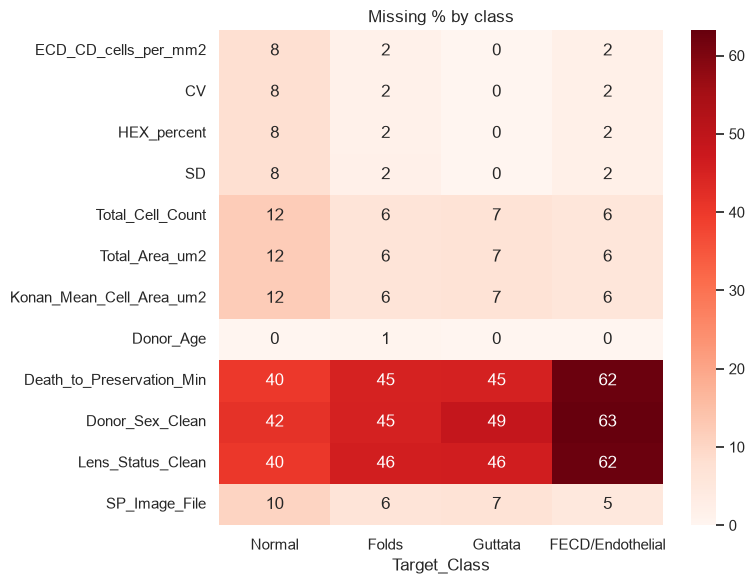

In [16]:
check_cols = konan_cols + ["Donor_Age", "Death_to_Preservation_Min",
                           "Donor_Sex_Clean", "Lens_Status_Clean", "SP_Image_File"]
miss_by_class = (df.groupby("Target_Class")[check_cols]
                   .apply(lambda g: g.isna().mean() * 100).round(1).T[CLASS_ORDER])
display(miss_by_class)

plt.figure(figsize=(8, 6))
sns.heatmap(miss_by_class, annot=True, fmt=".0f", cmap="Reds")
plt.title("Missing % by class"); plt.tight_layout(); plt.show()

### 6.3 Feature distributions by class

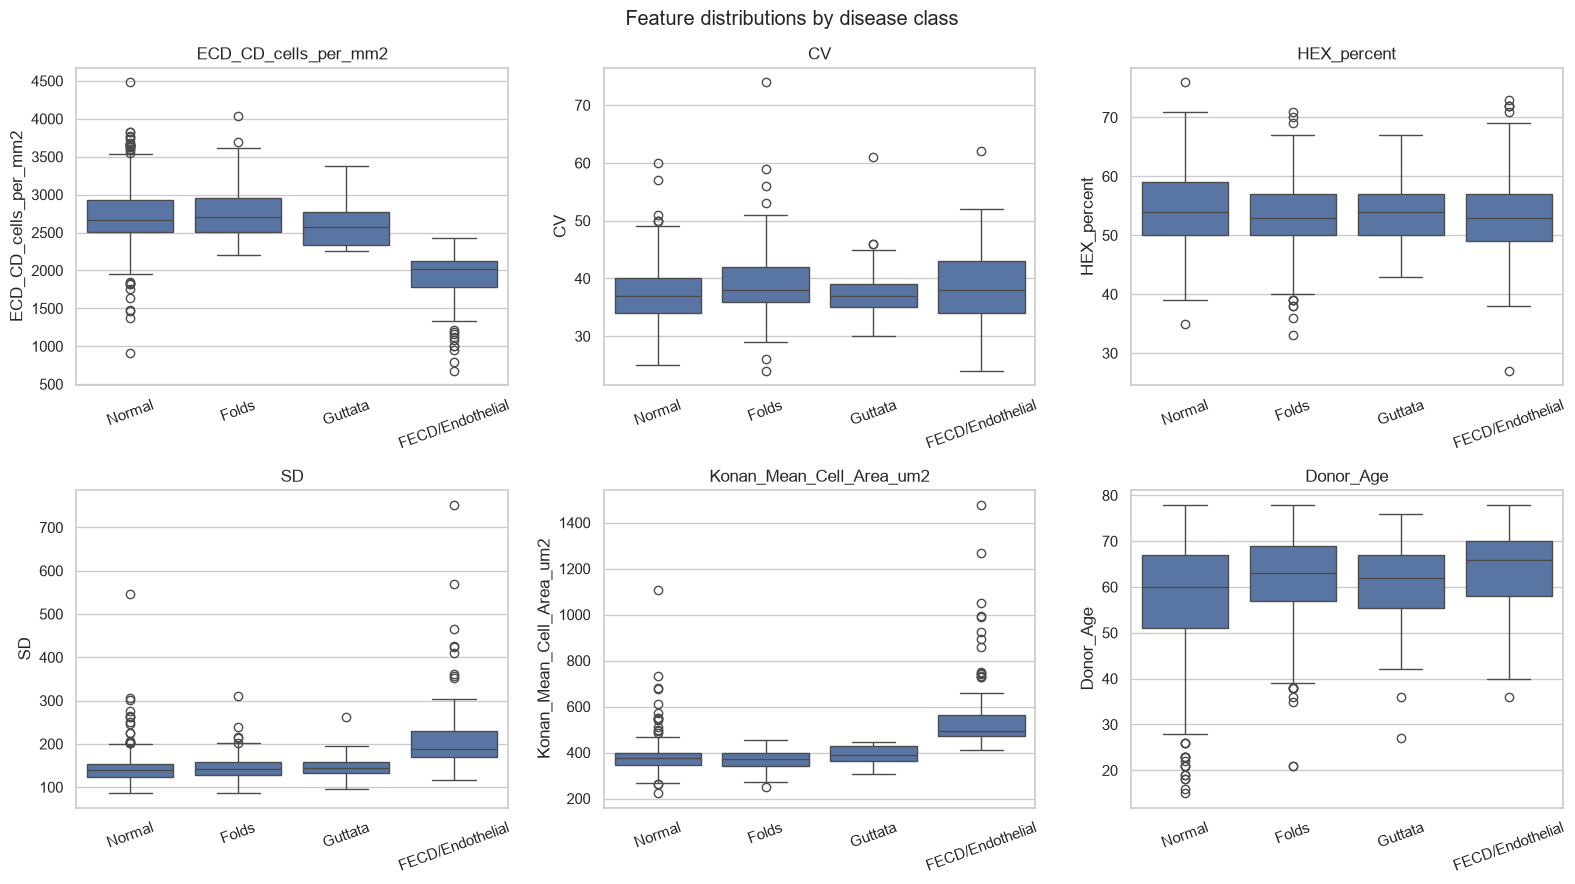

In [17]:
plot_feats = ["ECD_CD_cells_per_mm2", "CV", "HEX_percent", "SD",
              "Konan_Mean_Cell_Area_um2", "Donor_Age"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), plot_feats):
    sns.boxplot(data=df, x="Target_Class", y=col, order=CLASS_ORDER, ax=ax)
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
plt.suptitle("Feature distributions by disease class")
plt.tight_layout(); plt.show()

### 6.4 Statistical separability (effect size)
Kruskal–Wallis tests whether the classes differ at all; **Cliff's delta** measures how strongly each class differs from Normal.
`|d| < 0.15` negligible · `< 0.33` small · `< 0.47` medium · `≥ 0.47` large

In [18]:
def cliffs_delta(a, b):
    u = mannwhitneyu(a, b).statistic
    return 2 * u / (len(a) * len(b)) - 1

res = []
for col in plot_feats:
    groups = [df.loc[df["Target_Class"] == c, col].dropna() for c in CLASS_ORDER]
    h, p = kruskal(*groups)
    row = {"Feature": col, "Kruskal_H": round(h, 1), "Kruskal_p": f"{p:.2e}"}
    for name, g in zip(CLASS_ORDER[1:], groups[1:]):
        row[f"d_{name}_vs_Normal"] = round(cliffs_delta(g, groups[0]), 2)
    res.append(row)
separability = pd.DataFrame(res)
separability

,Feature,Kruskal_H,Kruskal_p,d_Folds_vs_Normal,d_Guttata_vs_Normal,d_FECD/Endothelial_vs_Normal
0,ECD_CD_cells_per_mm2,331.1,1.89e-71,0.02,-0.21,-0.95
1,CV,16.2,1.04e-03,0.16,-0.01,0.11
2,HEX_percent,7.5,5.70e-02,-0.11,-0.02,-0.09
3,SD,233.5,2.45e-50,0.09,0.17,0.82
4,Konan_Mean_Cell_Area_um2,317.1,1.98e-68,-0.02,0.21,0.95
5,Donor_Age,43.6,1.86e-09,0.18,0.10,0.33


### 6.5 Severity within each disease class

In [19]:
for cls in CLASS_ORDER[1:]:
    sub = df[(df["Target_Class"] == cls) & df["Target_Severity"].isin(SEV_ORDER)]
    print(f"\n=== {cls} (n={len(sub)}) ===")
    display(sub.groupby("Target_Severity")[plot_feats[:5]].median().round(1))
    for col in ["ECD_CD_cells_per_mm2", "CV", "HEX_percent", "SD"]:
        a = sub.loc[sub["Target_Severity"] == "Moderate+Severe", col].dropna()
        b = sub.loc[sub["Target_Severity"] == "Mild", col].dropna()
        if len(a) > 2 and len(b) > 2:
            print(f"  {col:22s} Cliff's d = {cliffs_delta(a, b):+.2f}   p = {mannwhitneyu(a, b).pvalue:.3g}")


=== Folds (n=324) ===


,ECD_CD_cells_per_mm2,CV,HEX_percent,SD,Konan_Mean_Cell_Area_um2
Target_Severity,,,,,
Mild,2713.5,38.0,53.0,141.0,370.0
Moderate+Severe,2525.0,38.0,53.0,145.0,396.0


  ECD_CD_cells_per_mm2   Cliff's d = -0.19   p = 0.0961
  CV                     Cliff's d = -0.04   p = 0.704
  HEX_percent            Cliff's d = -0.04   p = 0.713
  SD                     Cliff's d = +0.11   p = 0.318

=== Guttata (n=84) ===


,ECD_CD_cells_per_mm2,CV,HEX_percent,SD,Konan_Mean_Cell_Area_um2
Target_Severity,,,,,
Mild,2590.5,37.0,55.0,141.0,388.0
Moderate+Severe,2561.0,39.0,52.0,162.5,390.5


  ECD_CD_cells_per_mm2   Cliff's d = -0.17   p = 0.338
  CV                     Cliff's d = +0.50   p = 0.00604
  HEX_percent            Cliff's d = -0.30   p = 0.0969
  SD                     Cliff's d = +0.50   p = 0.00553

=== FECD/Endothelial (n=136) ===


,ECD_CD_cells_per_mm2,CV,HEX_percent,SD,Konan_Mean_Cell_Area_um2
Target_Severity,,,,,
Mild,2047.0,38.0,53.0,184.0,489.0
Moderate+Severe,1366.0,40.0,53.0,271.0,730.0


  ECD_CD_cells_per_mm2   Cliff's d = -0.70   p = 1.88e-08
  CV                     Cliff's d = +0.13   p = 0.297
  HEX_percent            Cliff's d = -0.05   p = 0.683
  SD                     Cliff's d = +0.66   p = 1.5e-07


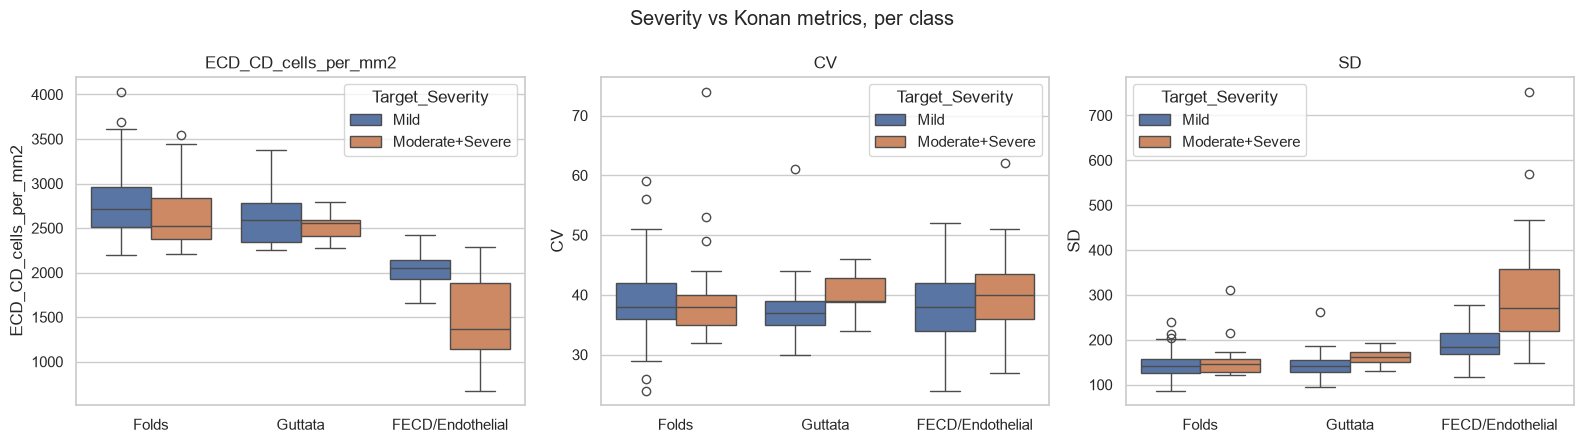

In [20]:
sub = df[df["Target_Severity"].isin(SEV_ORDER)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["ECD_CD_cells_per_mm2", "CV", "SD"]):
    sns.boxplot(data=sub, x="Target_Class", y=col, hue="Target_Severity",
                order=CLASS_ORDER[1:], hue_order=SEV_ORDER, ax=ax)
    ax.set_title(col); ax.set_xlabel("")
plt.suptitle("Severity vs Konan metrics, per class")
plt.tight_layout(); plt.show()

### 6.6 Is *Low cell density* a threshold rule on ECD?
If the label was assigned from an ECD cut-off, a model using ECD is just re-learning that rule — worth stating in the report.

ECD < 2000: non-LCD below =  13 | LCD at/above =  73
ECD < 2100: non-LCD below =  17 | LCD at/above =  31
ECD < 2200: non-LCD below =  20 | LCD at/above =   8
ECD < 2300: non-LCD below =  81 | LCD at/above =   0
ECD < 2400: non-LCD below = 169 | LCD at/above =   0


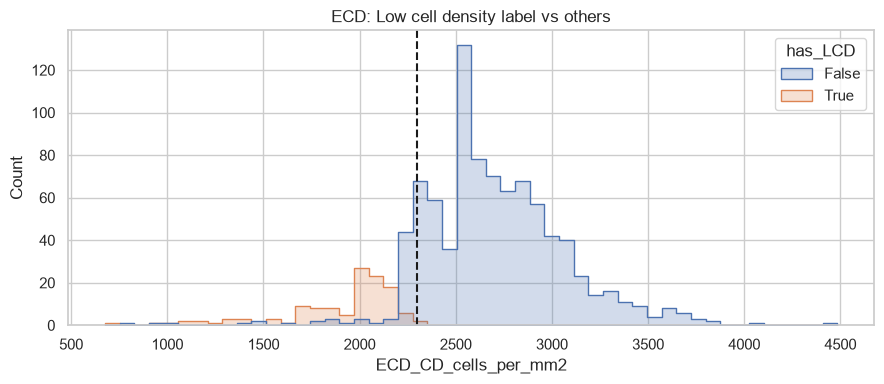

In [21]:
d = df[df["Has_Konan"]]
for t in [2000, 2100, 2200, 2300, 2400]:
    print(f"ECD < {t}: non-LCD below = {(d.loc[~d['has_LCD'], 'ECD_CD_cells_per_mm2'] < t).sum():3d} | "
          f"LCD at/above = {(d.loc[d['has_LCD'], 'ECD_CD_cells_per_mm2'] >= t).sum():3d}")

plt.figure(figsize=(9, 4))
sns.histplot(data=d, x="ECD_CD_cells_per_mm2", hue="has_LCD", bins=50, element="step")
plt.axvline(2300, ls="--", c="k")
plt.title("ECD: Low cell density label vs others"); plt.tight_layout(); plt.show()

### 6.7 Correlation and redundancy

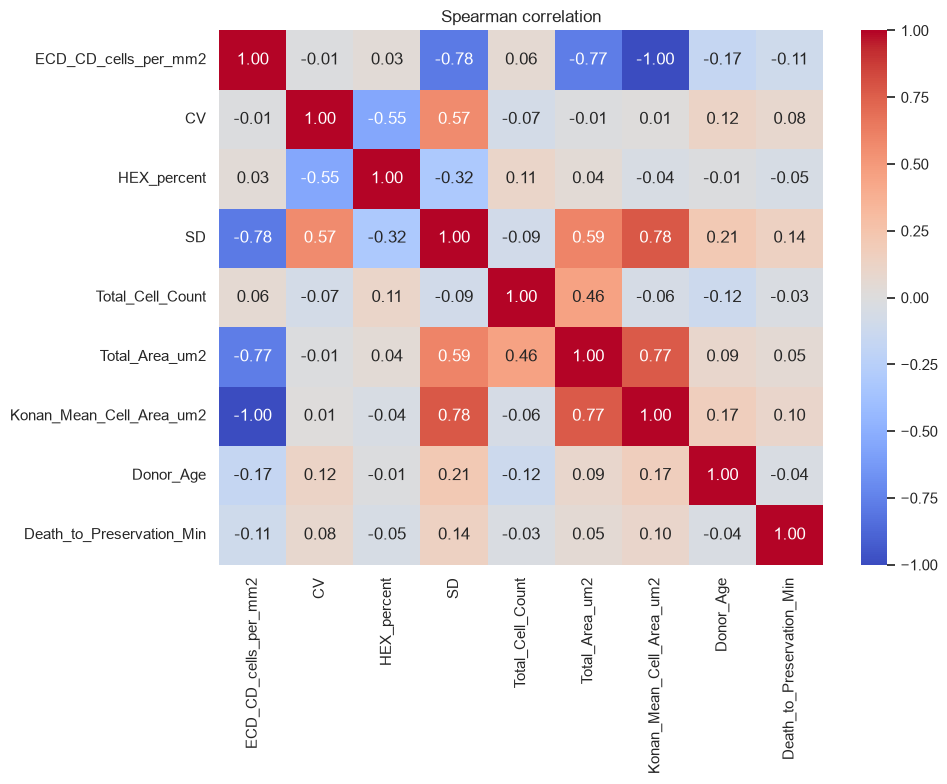

Pairs with |rho| >= 0.7:


rho
ECD_CD_cells_per_mm2 SD                       -0.78
                     Total_Area_um2           -0.77
                     Konan_Mean_Cell_Area_um2 -1.00
SD                   Konan_Mean_Cell_Area_um2  0.78
Total_Area_um2       Konan_Mean_Cell_Area_um2  0.77

In [22]:
corr = df[num_feats].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation"); plt.tight_layout(); plt.show()

up = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("Pairs with |rho| >= 0.7:")
up[up.abs() >= 0.7].round(2).to_frame("rho")

### 6.8 Mutual information (overall and one-vs-rest)

In [23]:
mi_feats = konan_cols + ["Donor_Age", "Eye_Right"]
mi_df = df[df["Has_Konan"]].copy()
X = mi_df[mi_feats].fillna(mi_df[mi_feats].median())
y = mi_df["Target_Class"]

mi = pd.Series(mutual_info_classif(X, y, random_state=42), index=mi_feats)
display(mi.sort_values(ascending=False).round(3).to_frame("MI_all_classes"))

ovr = {c: mutual_info_classif(X, (y == c).astype(int), random_state=42) for c in CLASS_ORDER}
pd.DataFrame(ovr, index=mi_feats).round(3)

,MI_all_classes
ECD_CD_cells_per_mm2,0.331
Konan_Mean_Cell_Area_um2,0.326
SD,0.155
Total_Area_um2,0.143
Total_Cell_Count,0.044
Donor_Age,0.025
HEX_percent,0.000
CV,0.000
Eye_Right,0.000


,Normal,Folds,Guttata,FECD/Endothelial
ECD_CD_cells_per_mm2,0.072,0.062,0.019,0.302
CV,0.000,0.000,0.000,0.000
HEX_percent,0.000,0.000,0.005,0.007
SD,0.035,0.016,0.005,0.157
Total_Cell_Count,0.003,0.000,0.012,0.029
Total_Area_um2,0.034,0.023,0.003,0.127
Konan_Mean_Cell_Area_um2,0.080,0.069,0.015,0.287
Donor_Age,0.016,0.000,0.000,0.035
Eye_Right,0.000,0.000,0.003,0.000


### 6.9 Konan-only baseline (donor-grouped CV)
A shallow decision tree shows what the tabular Konan features can achieve on their own. Folds are split by donor.

In [24]:
base_feats = ["ECD_CD_cells_per_mm2", "CV", "HEX_percent", "SD", "Donor_Age"]
cv  = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
clf = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42)

Xb = mi_df[base_feats].fillna(mi_df[base_feats].median())
pred = cross_val_predict(clf, Xb, mi_df["Target_Class"], cv=cv, groups=mi_df["Donor_Group"])
print("Disease class — Konan only")
print(classification_report(mi_df["Target_Class"], pred, zero_division=0))

sev_df = mi_df[mi_df["Target_Severity"].isin(SEV_ORDER)]
Xs = sev_df[base_feats].fillna(sev_df[base_feats].median())
ps = cross_val_predict(clf, Xs, sev_df["Target_Severity"], cv=cv, groups=sev_df["Donor_Group"])
print("Severity (diseased rows) — Konan only")
print(classification_report(sev_df["Target_Severity"], ps, zero_division=0))

Disease class — Konan only
                  precision    recall  f1-score   support

FECD/Endothelial       0.82      0.90      0.86       133
           Folds       0.42      0.41      0.41       319
         Guttata       0.11      0.43      0.18        84
          Normal       0.61      0.29      0.39       463

        accuracy                           0.42       999
       macro avg       0.49      0.51      0.46       999
    weighted avg       0.54      0.42      0.44       999

Severity (diseased rows) — Konan only
                 precision    recall  f1-score   support

           Mild       0.90      0.77      0.83       468
Moderate+Severe       0.20      0.38      0.26        68

       accuracy                           0.72       536
      macro avg       0.55      0.58      0.54       536
   weighted avg       0.81      0.72      0.76       536



### 6.10 Image availability and basic image quality

,Has_SP_Image,Has_C_Image,Has_Konan
Target_Class,,,
Normal,451,451,463
Folds,303,303,319
Guttata,78,78,84
FECD/Endothelial,129,129,133


SP images listed but not on disk: 619


,,Count
W,H,
1296,972,342


,Mean_Intensity,Contrast_STD
Target_Class,,
FECD/Endothelial,88.0,44.3
Folds,76.6,43.3
Guttata,75.7,46.6
Normal,81.7,47.1


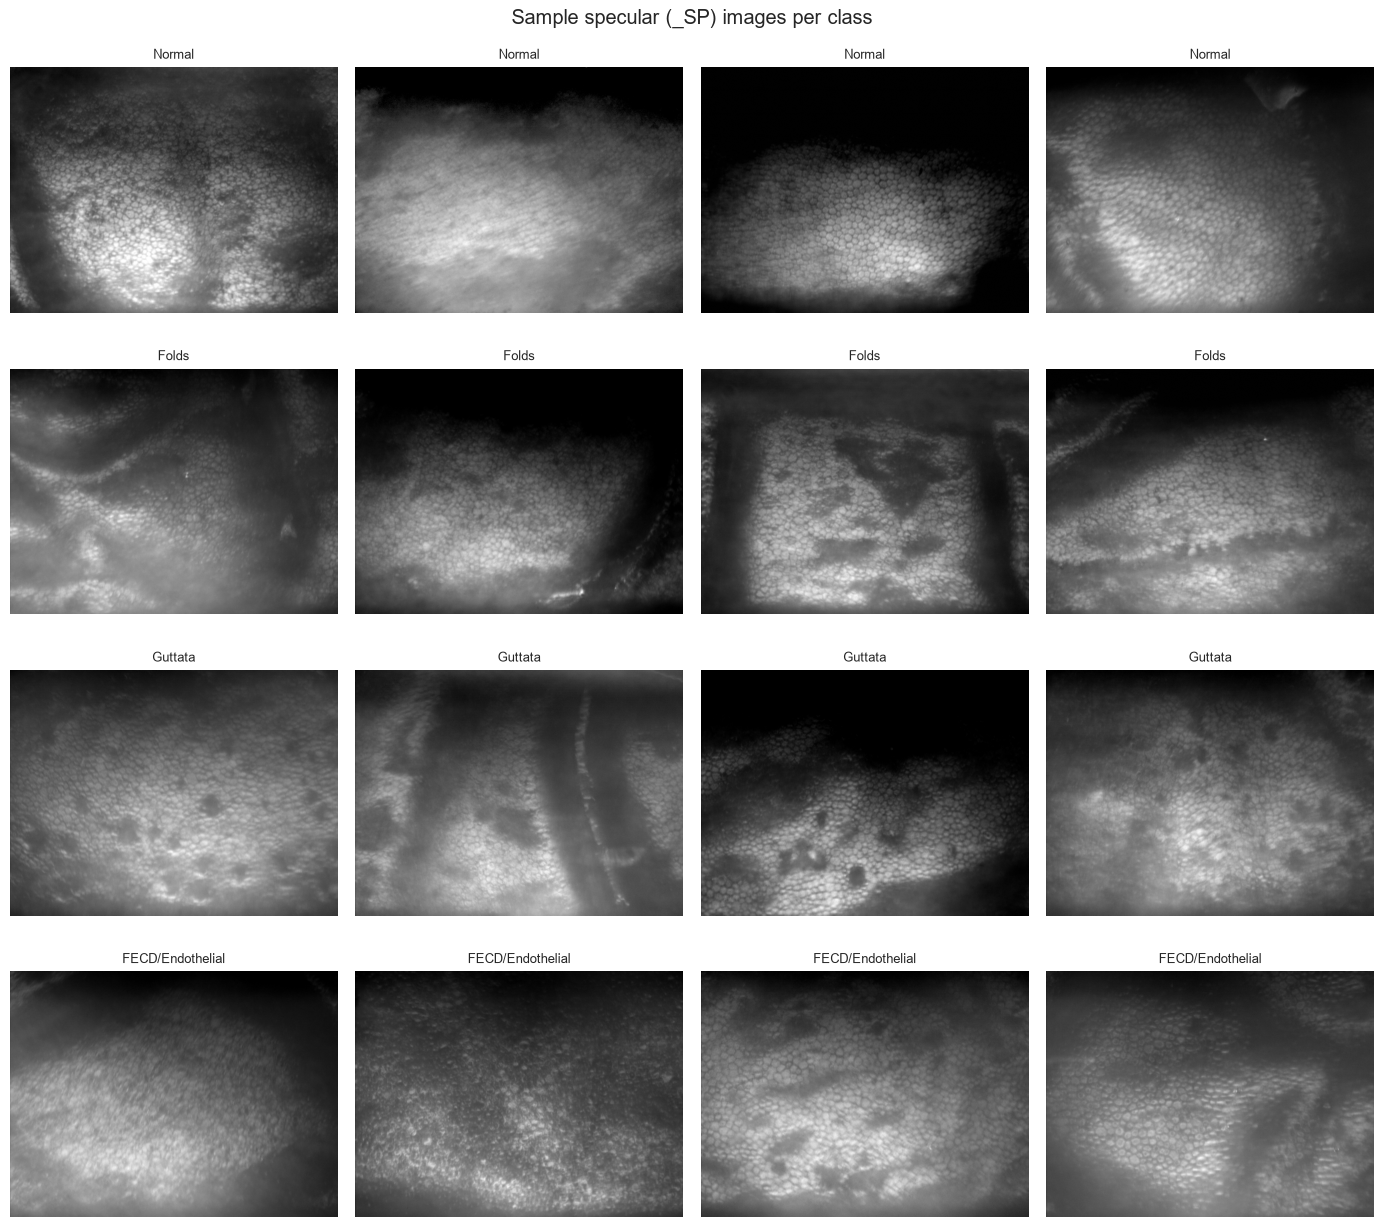

In [25]:
df["Has_SP_Image"] = df["SP_Image_File"].notna()
df["Has_C_Image"]  = df["Cell_Image_File"].notna()
display(df.groupby("Target_Class")[["Has_SP_Image", "Has_C_Image", "Has_Konan"]].sum().reindex(CLASS_ORDER))

if os.path.isdir(IMAGE_DIR):
    from PIL import Image
    paths = {f: os.path.join(r, f) for r, _, fs in os.walk(IMAGE_DIR) for f in fs}
    df["SP_Found"] = df["SP_Image_File"].isin(paths.keys())
    print("SP images listed but not on disk:", (df["Has_SP_Image"] & ~df["SP_Found"]).sum())

    stats = []
    for f in df.loc[df["SP_Found"], "SP_Image_File"]:
        im = Image.open(paths[f]).convert("L"); a = np.asarray(im, dtype=float)
        stats.append({"SP_Image_File": f, "W": im.width, "H": im.height,
                      "Mean_Intensity": a.mean(), "Contrast_STD": a.std()})
    img_stats = pd.DataFrame(stats).merge(df[["SP_Image_File", "Target_Class"]], on="SP_Image_File")
    display(img_stats.groupby(["W", "H"]).size().to_frame("Count"))
    display(img_stats.groupby("Target_Class")[["Mean_Intensity", "Contrast_STD"]].median().round(1))

    fig, axes = plt.subplots(len(CLASS_ORDER), 4, figsize=(14, 3.2 * len(CLASS_ORDER)))
    for i, cls in enumerate(CLASS_ORDER):
        files = img_stats.loc[img_stats["Target_Class"] == cls, "SP_Image_File"].sample(
            min(4, (img_stats["Target_Class"] == cls).sum()), random_state=1)
        for j in range(4):
            ax = axes[i, j]; ax.axis("off")
            if j < len(files):
                ax.imshow(Image.open(paths[files.iloc[j]]).convert("L"), cmap="gray")
                ax.set_title(cls, fontsize=9)
    plt.suptitle("Sample specular (_SP) images per class"); plt.tight_layout(); plt.show()
else:
    df["SP_Found"] = np.nan
    print("IMAGE_DIR not found - set IMAGE_DIR in the Setup cell to run the image checks")

## 7. Feature decisions
Every original column gets an explicit decision and reason.

In [26]:
leakage = ["Tissue_Grade", "Overall_Donor_Quality", "Transplant_Suitability",
           "Suitability_Reason", "Descemet_Findings", "Descemet_Severity",
           "Endothelium_Findings", "Endothelium_Severity", "Review_Notes",
           "Grade_Request_Met", "Requested_Grade", "Intended_Use", "Tissue_Outcome",
           "Disease_Label_Source", "Tissue_Grade_Source", "Merge_Filled_Columns",
           "Needs_Review", "Form_ECD_cells_per_mm2"]
identifiers = ["Tissue_ID", "Image_ID", "Tissue_Serial", "Source_PDF", "PDF_Pages",
               "Konan_Report_File", "SP_Image_File", "Cell_Image_File",
               "Konan_Raw_CorneaID", "Konan_Comments", "Konan_Exam_Date",
               "Request_Reg_No", "Request_Issue_No", "Dataset_Part", "Linkage_Status"]
recipient = ["Recipient_Age", "Recipient_Eye", "Recipient_Indication",
             "Request_Indication", "Previous_Grafts", "Primary_Procedure",
             "Secondary_Procedures", "Surgery_Date", "Donor_Graft_Size_mm",
             "Recipient_Bed_Size_mm", "Suture_Technique", "Intraop_Complications",
             "Death_to_Surgery_Days", "Request_Date", "Proposed_Op_Date",
             "Request_Urgency", "Request_Indication_Type", "Recipient_Sex",
             "VA_Operative_Eye", "VA_Fellow_Eye", "Planned_Procedure",
             "Requesting_Surgeon", "Requesting_Hospital", "Request_to_Surgery_Days"]
other_layers = ["Epithelium_Findings", "Epithelium_Severity", "Stroma_Findings",
                "Stroma_Severity", "Additional_Findings"]
donor_medical = ["Primary_COD", "Admitting_Diagnosis", "Serology_HBsAg", "Serology_HCV",
                 "Serology_HIV", "Serology_VDRL", "Storage_Medium",
                 "Death_Date_Time", "Preservation_Date_Time"]
targets = ["Disease_Label", "Disease_Severity"]
keep_konan = ["ECD_CD_cells_per_mm2", "CV", "HEX_percent", "SD", "Total_Cell_Count"]
redundant = {"Konan_Mean_Cell_Area_um2": "rho = -1.00 with ECD (same information)",
             "Total_Area_um2": "Analysis-area size; rho ~ -0.77 with ECD, not a biomarker"}
keep_donor = {"Donor_Age": "Donor_Age", "Donor_Sex": "-> Donor_Sex_Clean", "Eye": "-> Eye_Right",
              "Lens_Status": "-> Lens_Status_Clean",
              "Death_to_Preservation_Time": "-> Death_to_Preservation_Min"}

def decide(c):
    if c in targets:       return "Target", "Raw label; encoded as Target_Class / Target_Severity"
    if c in leakage:       return "Exclude - leakage", "Written by grader who already knew the diagnosis/grade"
    if c in identifiers:   return "Exclude - identifier", "ID / filename / admin; used only for linking"
    if c in recipient:     return "Exclude - post-outcome", "Recipient/surgery info, not available at grading time"
    if c in other_layers:  return "Exclude - other layer", "Epithelium/stroma findings; not endothelial, ~45-70% missing"
    if c in donor_medical: return "Exclude - sparse/irrelevant", "Mostly missing or not related to endothelial disease"
    if c in redundant:     return "Exclude - redundant", redundant[c]
    if c in keep_konan:    return "Keep - Konan biomarker", "Quantitative endothelial metric"
    if c in keep_donor:    return "Keep - donor context", f"Cleaned {keep_donor[c]}; ~45% missing for form-less rows"
    return "Review", "Not yet decided"

feature_decisions = pd.DataFrame(
    [{"Column": c, "Missing_%": round(df[c].isna().mean() * 100, 1),
      "Decision": decide(c)[0], "Reason": decide(c)[1]} for c in ORIGINAL_COLS])

display(feature_decisions["Decision"].value_counts().to_frame("Columns"))
feature_decisions

,Columns
Decision,
Exclude - post-outcome,24
Exclude - leakage,18
Exclude - identifier,15
Exclude - sparse/irrelevant,9
Keep - donor context,5
Keep - Konan biomarker,5
Exclude - other layer,5
Target,2
Exclude - redundant,2


,Column,Missing_%,Decision,Reason
0,Tissue_ID,0.0,Exclude - identifier,ID / filename / admin; used only for linking
1,Eye,0.0,Keep - donor context,Cleaned -> Eye_Right; ~45% missing for form-less rows
2,Image_ID,1.1,Exclude - identifier,ID / filename / admin; used only for linking
3,Disease_Label,0.0,Target,Raw label; encoded as Target_Class / Target_Severity
4,Disease_Severity,48.1,Target,Raw label; encoded as Target_Class / Target_Severity
...,...,...,...,...
80,Tissue_Grade_Source,1.6,Exclude - leakage,Written by grader who already knew the diagnosis/grade
81,Disease_Label_Source,0.0,Exclude - leakage,Written by grader who already knew the diagnosis/grade
82,Needs_Review,100.0,Exclude - leakage,Written by grader who already knew the diagnosis/grade
83,Review_Notes,73.0,Exclude - leakage,Written by grader who already knew the diagnosis/grade


## 8. Save cleaned outputs

In [27]:
save_cols = (["Tissue_ID", "Donor_Group", "Eye", "SP_Image_File", "Cell_Image_File",
              "Disease_Label", "Disease_Severity", "Target_Class", "Target_Severity",
              "has_FECD", "has_LCD", "has_POLY", "has_GUTT", "has_FOLDS",
              "Has_Konan", "Has_SP_Image", "Flag_Eye_Mismatch", "Flag_ECD_Mismatch",
              "Flag_Implausible"]
             + konan_cols +
             ["Donor_Age", "Donor_Sex_Clean", "Eye_Right", "Lens_Status_Clean",
              "Death_to_Preservation_Min"])
clean_df = df[save_cols].copy()

clean_path = os.path.join(OUTPUT_DIR, "Cleaned_Dataset.csv")
dec_path   = os.path.join(OUTPUT_DIR, "Feature_Decisions.csv")
clean_df.to_csv(clean_path, index=False)
feature_decisions.to_csv(dec_path, index=False)
print("Saved:", clean_path, clean_df.shape)
print("Saved:", dec_path)

Saved: C:\Users\minsa_\Downloads\Cleaned_Dataset.csv (1048, 31)
Saved: C:\Users\minsa_\Downloads\Feature_Decisions.csv


## 9. EDA conclusions (to carry into feature engineering)
Fill these in from the outputs above. Results from the run on `Combined_Research_Dataset_Final.xlsx`:

1. **Targets.** Four classes: Normal (504), Folds (324), FECD/Endothelial (136), Guttata (84). FECD, Low cell density and Polymorphism co-occur almost always, so they are one class. Severity: Mild (475) vs Moderate+Severe (70).
2. **Konan metrics separate FECD only.** ECD (Cliff's d ≈ −0.95) and SD (≈ +0.82) strongly separate FECD from Normal. For Folds and Guttata all effects are negligible to small, so **image features are required** for those classes.
3. **Severity.** For FECD, ECD separates Mild from Moderate+Severe strongly (d ≈ −0.70). For Folds there is no meaningful difference in the tabular data.
4. **Low cell density ≈ ECD < 2300.** The label appears to be rule-based on ECD.
5. **Redundancy.** `Konan_Mean_Cell_Area_um2` is the reciprocal of ECD (ρ = −1.00), so it is dropped.
6. **Missingness depends on class.** Donor/form fields are missing ~63% for FECD vs ~41% for Normal, so they need missing-indicators, not blind imputation.
7. **Donor leakage.** ~234 donors contribute both eyes, so all splits must be grouped by `Donor_Group`.
8. **Baseline.** Konan-only, donor-grouped: FECD F1 ≈ 0.87, but Folds ≈ 0.38, Normal ≈ 0.43, Guttata ≈ 0.19; macro-F1 ≈ 0.47.